<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.7; font-family: 'Segoe UI', Arial, sans-serif;">

# מאפייני מערך הכליאה בארה"ב
### ניתוח בסיס הנתונים הלאומי (HIFLD) והפקת לקחים יישומיים למערך שירות בתי הסוהר
**מגישה:** נועה בוחניק - 322634106  
**בסיס הנתונים:** שכבת הנתונים הגיאוגרפית של מתקני הכליאה בארה"ב (`Prison_Boundaries.csv`, סך הכל 6,737 מתקנים)

---
### רקע ותמצית מנהלים:
במסגרת עבודה זו נותח מאגר מתקני הכליאה הלאומי של ארה"ב (HIFLD), הכולל 6,737 מתקנים, במטרה לאפיין את פריסת המערך, לבחון את עומסי התפוסה ולגזור תובנות מעשיות עבור שירות בתי הסוהר בישראל.

**עיקרי הממצאים שעלו מן הניתוח:**

1. **תמונת התפוסה והעומס במתקנים ("פרדוקס הצפיפות"):** במבט כלל-ארצי, נתוני התפוסה הממוצעים עומדים על **86.7%**, נתון שעלול ליצור רושם מוטעה של איזון. בפועל, בחינה ברמת המתקן הבודד מצביעה על קיומה של בעיית צפיפות ממוקדת: כ-**23.5% מהמתקנים המדווחים (853 מתקנים)** פועלים מעבר לקיבולת המרבית שלהם (**מעל 100% תפוסה**). עומס זה בולט במיוחד במערך הפדרלי, שבו התפוסה הממוצעת חוצה את רף הקיבולת (**101.9%**).
2. **מאפייני כליאת נוער וקטינים (Juvenile Facilities):** מתקני הנוער מהווים כ-**18.2%** מכלל המתקנים בארה"ב (1,223 מתקנים). מודל הכליאה לנוער מושתת על מתקנים קטנים ומבוזרים (כ-**94 מקומות כליאה בממוצע למתקן**) ושיעור תפוסה ממוצע נמוך יחסית (**62.3%**). פריסה זו מאפשרת הפרדה מלאה מבגירים ושמירה על סביבה טיפולית וחינוכית.
3. **שונות גיאוגרפית ומדינתית:** הניתוח חושף פערים ניכרים בין מחוזות ואזורים גיאוגרפיים. בעוד שבמדינות הדרום והמערב קיימים שיעורי צפיפות גבוהים במיוחד (כגון קנטקי עם כ-**64.8%** מתקנים בתפוסת יתר, טנסי עם **36.4%** וקליפורניה עם **35.1%**), באזורי הצפון-מזרח והמערב-התיכון ניכרת מגמה של תת-תפוסה, הנובעת בין היתר ממדיניות מקומית לצמצום כליאה.
</div>

<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.6; font-family: 'Segoe UI', Arial, sans-serif;">

### שלב 1: טעינת ספריות, הגדרות עימוד ותרשימים
</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from IPython.display import display, HTML
from bidi.algorithm import get_display

warnings.filterwarnings('ignore')

# הגדרות תצוגה
%matplotlib inline
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 1000)
plt.rcParams['figure.figsize'] = (16, 11)
plt.rcParams['font.size'] = 11

def rtl(text):
    if not isinstance(text, str):
        return text
    return get_display(text)

def show_rtl_table(df_table, title=""):
    html = f'''<div dir="rtl" style="text-align: right; direction: rtl; unicode-bidi: embed; font-family: 'Segoe UI', Arial, sans-serif; margin: 16px 0; background-color: #ffffff; padding: 14px; border-radius: 8px; box-shadow: 0 3px 8px rgba(0,0,0,0.1); border: 1.5px solid #cbd5e1;">
    <div style="font-size: 15px; font-weight: 700; color: #1e3a8a; border-bottom: 2px solid #2563eb; padding-bottom: 6px; margin-bottom: 10px; text-align: right;">{title}</div>
    <table style="direction: rtl; text-align: right; width: 100%; border-collapse: collapse; font-size: 13px; background-color: #ffffff; color: #000000;">
        <thead>
            <tr style="background-color: #0f172a; color: #ffffff;">
'''
    for col in df_table.columns:
        html += f'                <th style="padding: 10px 12px; text-align: right; border: 1px solid #334155; font-weight: 700; color: #ffffff !important; background-color: #0f172a; font-size: 13px;">{col}</th>\n'
    html += '            </tr>\n        </thead>\n        <tbody>\n'
    for i, row in df_table.iterrows():
        bg = '#f1f5f9' if i % 2 == 0 else '#ffffff'
        html += f'            <tr style="background-color: {bg};">\n'
        for val in row:
            html += f'                <td style="padding: 8px 12px; text-align: right; border: 1px solid #cbd5e1; color: #000000 !important; font-weight: 600; font-size: 12.5px; background-color: {bg};">{val}</td>\n'
        html += '            </tr>\n'
    html += '''        </tbody>
    </table>
</div>'''
    display(HTML(html))


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.7; font-family: 'Segoe UI', Arial, sans-serif;">

---
# פרק א': ניתוח מאפייני המאגר המקורי 

</div>

In [2]:
df_raw = pd.read_csv('Prison_Boundaries.csv', low_memory=False)
df = df_raw.copy()

# מיפוי 4 סוגי ניהול עיקריים
type_map = {
    'COUNTY': 'מחוזי (בתי מעצר)',
    'STATE': 'מדינתי (בתי כלא שפוטים)',
    'LOCAL': 'עירוני ומקומי',
    'FEDERAL': 'פדרלי (כליאה פדרלית)'
}

# 4 אזורי מפקד האוכלוסין בארה"ב
census_regions = {
    'Northeast': ['CT', 'ME', 'MA', 'NH', 'RI', 'VT', 'NJ', 'NY', 'PA'],
    'Midwest': ['IL', 'IN', 'MI', 'OH', 'WI', 'IA', 'KS', 'MN', 'MO', 'NE', 'ND', 'SD'],
    'South': ['DE', 'FL', 'GA', 'MD', 'NC', 'SC', 'VA', 'DC', 'WV', 'AL', 'KY', 'MS', 'TN', 'AR', 'LA', 'OK', 'TX'],
    'West': ['AZ', 'CO', 'ID', 'MT', 'NV', 'NM', 'UT', 'WY', 'AK', 'CA', 'HI', 'OR', 'WA']
}
state_to_region = {state: reg for reg, states in census_regions.items() for state in states}
region_hebrew = {'South': 'דרום', 'West': 'מערב', 'Midwest': 'מערב תיכון', 'Northeast': 'צפון מזרח'}

df['REGION'] = df['STATE'].map(state_to_region).fillna('Other')
df['אזור_גיאוגרפי'] = df['REGION'].map(region_hebrew).fillna('אחר')

print(f"✓ נטענו בהצלחה {len(df):,} מתקנים מתוך קובץ Prison_Boundaries.csv.")


✓ נטענו בהצלחה 6,738 מתקנים מתוך קובץ Prison_Boundaries.csv.


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.6; font-family: 'Segoe UI', Arial, sans-serif;">

### סוגי ניהול עיקריים ואימות מקורות המיפוי המרחבי
</div>

In [3]:
# 1. התפלגות 4 סוגי הניהול המרכזיים
type_clean_df = df[df['TYPE'].isin(type_map.keys())]['TYPE'].map(type_map).value_counts().reset_index()
type_clean_df.columns = ['סוג ניהול', 'כמות מתקנים']
type_clean_df['אחוז מסך המאגר'] = (type_clean_df['כמות מתקנים'] / len(df) * 100).round(1).astype(str) + '%'
type_clean_df['כמות מתקנים'] = type_clean_df['כמות מתקנים'].apply(lambda x: f"{x:,}")

show_rtl_table(type_clean_df, "טבלה 1: התפלגות מתקני כליאה לפי סוג ניהול (N=6,737)")

# 2. אימות מקורות מיפוי וצילומי לוויין
source_df = df['SOURCE'].value_counts().head(5).reset_index()
source_df.columns = ['מקור מידע / מיפוי', 'כמות מתקנים']
source_df['אחוז מהמאגר'] = (source_df['כמות מתקנים'] / len(df) * 100).round(1).astype(str) + '%'
source_df['כמות מתקנים'] = source_df['כמות מתקנים'].apply(lambda x: f"{x:,}")

show_rtl_table(source_df, "טבלה 2: אימות מקורות מידע ואיכות מיפוי מרחבי")


סוג ניהול,כמות מתקנים,אחוז מסך המאגר
מחוזי (בתי מעצר),"3,770",56.0%
מדינתי (בתי כלא שפוטים),"2,273",33.7%
עירוני ומקומי,372,5.5%
פדרלי (כליאה פדרלית),257,3.8%


מקור מידע / מיפוי,כמות מתקנים,אחוז מהמאגר
"https://www.texastribune.org/library/data/texas-prisons/units/, http://www.tdcj.state.tx.us/unit_directory/index.html",99,1.5%
"http://www.bop.gov/about/statistics/population_statistics.jsp, http://jayhurst.net/wp-content/uploads/2013/09/16-0216_Capacities_PP80_population_report.pdf",71,1.1%
"http://www.dc.state.fl.us/pub/pop/, http://www.dc.state.fl.us/org/facilitydir.html",61,0.9%
http://www.dc.state.fl.us/pub/pop/,60,0.9%
"http://www.cor.pa.gov/Facilities/CountyPrisons/Pages/Inspection-Schedule,-Statistics-And-General-Info.aspx, http://www.cor.pa.gov/Facilities/CountyPrisons/Pages/County-Prison-Contact-Info.aspx",48,0.7%


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.6; font-family: 'Segoe UI', Arial, sans-serif;">

### התפלגות רמות אבטחה, קטגוריות עומס ופערים בארבעת אזורי המפקד
</div>

In [4]:
sec_risk_map = {
    'JUVENILE': ('נוער וקטינים', 'סיכון שיקומי / הפרדה מלאה', 'מתקני קטינים ייעודיים, ביזור מרחבי גבוה'),
    'MAXIMUM': ('אבטחה מקסימלית', 'סיכון גבוה ביותר / ביטחוני', 'חומות כפולות, אגפי הפרדה, שמירה הדוקה'),
    'MINIMUM': ('אבטחה מינימלית', 'סיכון נמוך / עבודות חוץ', 'מחנות עבודה ושיקום, ללא גדרות מסיביות'),
    'MEDIUM': ('אבטחה בינונית', 'סיכון בינוני / שפוטים כללי', 'מערך גדרות כפול ופיקוח שוטף'),
    'CLOSE': ('אבטחה סגורה', 'סיכון מוגבר / בידוד', 'השגחה פנימית מוגברת ובידוד תנועה'),
    'NOT AVAILABLE': ('לא מסווג / בתי מעצר', 'תחלופה מהירה / מעצר', 'בתי מעצר מחוזיים (County Jails)')
}

sec_counts = df['SECURELVL'].value_counts()
sec_table_data = []
for k in ['JUVENILE', 'MAXIMUM', 'MINIMUM', 'MEDIUM', 'CLOSE', 'NOT AVAILABLE']:
    if k in sec_counts:
        c = sec_counts[k]
        heb_name, risk_level, desc = sec_risk_map[k]
        sec_table_data.append({
            'רמת אבטחה': heb_name,
            'פרופיל סיכון': risk_level,
            'כמות מתקנים': f"{c:,}",
            'אחוז מהמאגר': f"{c/len(df)*100:.1f}%",
            'מאפייני תפעול': desc
        })

show_rtl_table(pd.DataFrame(sec_table_data), "טבלה 3: התפלגות רמות אבטחה ופרופיל סיכון במתקני הכליאה")

# מתקנים מדווחים (ללא -999)
df_open = df[df['STATUS'] == 'OPEN'].copy()
df_obs = df_open[(df_open['CAPACITY'] > 0) & (df_open['POPULATION'] >= 0)].copy()
df_obs['OCCUPANCY_RATE'] = (df_obs['POPULATION'] / df_obs['CAPACITY']) * 100

def get_occ_category(x):
    if x < 70: return 'תת-תפוסה (עד 70%)'
    elif x <= 90: return 'תפוסה תקינה (70% עד 90%)'
    elif x <= 100: return 'עומס גבוה (90% עד 100%)'
    else: return 'צפיפות יתר (מעל 100%)'

df_obs['OCC_CAT'] = df_obs['OCCUPANCY_RATE'].apply(get_occ_category)
occ_order = ['תת-תפוסה (עד 70%)', 'תפוסה תקינה (70% עד 90%)', 'עומס גבוה (90% עד 100%)', 'צפיפות יתר (מעל 100%)']
occ_summary = df_obs['OCC_CAT'].value_counts().loc[occ_order].reset_index()
occ_summary.columns = ['קטגוריית עומס', 'כמות מתקנים מדווחים']
occ_summary['אחוז מהמתקנים המדווחים'] = (occ_summary['כמות מתקנים מדווחים'] / len(df_obs) * 100).round(1).astype(str) + '%'
occ_summary['כמות מתקנים מדווחים'] = occ_summary['כמות מתקנים מדווחים'].apply(lambda x: f"{x:,}")

show_rtl_table(occ_summary, "טבלה 4: התפלגות מתקנים מדווחים לפי קטגוריות עומס (N=3,625)")

# טבלת פערים אזוריים
reg_summary = df_obs[df_obs['אזור_גיאוגרפי'] != 'אחר'].groupby('אזור_גיאוגרפי').agg(
    מתקנים=('FID', 'count'),
    קיבולת_כוללת=('CAPACITY', 'sum'),
    אוכלוסייה_כוללת=('POPULATION', 'sum'),
    תפוסה_ממוצעת=('OCCUPANCY_RATE', 'mean'),
    מתקנים_בצפיפות=('OCCUPANCY_RATE', lambda x: (x > 100).sum()),
    אחוז_בצפיפות=('OCCUPANCY_RATE', lambda x: (x > 100).mean() * 100),
    מתקנים_בתת_תפוסה=('OCCUPANCY_RATE', lambda x: (x < 70).sum()),
    אחוז_בתת_תפוסה=('OCCUPANCY_RATE', lambda x: (x < 70).mean() * 100)
).loc[['דרום', 'מערב', 'מערב תיכון', 'צפון מזרח']].reset_index()

reg_styled = pd.DataFrame({
    'אזור מפקד': reg_summary['אזור_גיאוגרפי'],
    'מתקנים מדווחים': reg_summary['מתקנים'].apply(lambda x: f"{x:,}"),
    'תפוסה ממוצעת': reg_summary['תפוסה_ממוצעת'].round(1).astype(str) + '%',
    'מתקנים בצפיפות (>100%)': reg_summary['מתקנים_בצפיפות'].apply(lambda x: f"{x:,}"),
    'אחוז בצפיפות יתר': reg_summary['אחוז_בצפיפות'].round(1).astype(str) + '%',
    'מתקנים בתת-תפוסה (<70%)': reg_summary['מתקנים_בתת_תפוסה'].apply(lambda x: f"{x:,}"),
    'אחוז בתת-תפוסה': reg_summary['אחוז_בתת_תפוסה'].round(1).astype(str) + '%'
})

show_rtl_table(reg_styled, "טבלה 5: השוואת עומסי תפוסה ופערים מרחביים ב-4 אזורי מפקד האוכלוסין")


רמת אבטחה,פרופיל סיכון,כמות מתקנים,אחוז מהמאגר,מאפייני תפעול
נוער וקטינים,סיכון שיקומי / הפרדה מלאה,"1,223",18.2%,"מתקני קטינים ייעודיים, ביזור מרחבי גבוה"
אבטחה מקסימלית,סיכון גבוה ביותר / ביטחוני,959,14.2%,"חומות כפולות, אגפי הפרדה, שמירה הדוקה"
אבטחה מינימלית,סיכון נמוך / עבודות חוץ,913,13.6%,"מחנות עבודה ושיקום, ללא גדרות מסיביות"
אבטחה בינונית,סיכון בינוני / שפוטים כללי,620,9.2%,מערך גדרות כפול ופיקוח שוטף
אבטחה סגורה,סיכון מוגבר / בידוד,169,2.5%,השגחה פנימית מוגברת ובידוד תנועה
לא מסווג / בתי מעצר,תחלופה מהירה / מעצר,"2,853",42.3%,בתי מעצר מחוזיים (County Jails)


קטגוריית עומס,כמות מתקנים מדווחים,אחוז מהמתקנים המדווחים
תת-תפוסה (עד 70%),"1,021",27.9%
תפוסה תקינה (70% עד 90%),909,24.9%
עומס גבוה (90% עד 100%),872,23.9%
צפיפות יתר (מעל 100%),853,23.3%


אזור מפקד,מתקנים מדווחים,תפוסה ממוצעת,מתקנים בצפיפות (>100%),אחוז בצפיפות יתר,מתקנים בתת-תפוסה (<70%),אחוז בתת-תפוסה
דרום,"1,741",86.4%,424,24.4%,474,27.2%
מערב,606,89.6%,164,27.1%,144,23.8%
מערב תיכון,892,85.4%,195,21.9%,287,32.2%
צפון מזרח,387,81.8%,69,17.8%,110,28.4%


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.6; font-family: 'Segoe UI', Arial, sans-serif;">

### מדדי קיבולת לפי סוג ניהול, מאפייני מתקני נוער וטופ 10 מדינות בצפיפות
</div>

In [5]:
# 6. מדדים לפי 4 סוגי ניהול
occ_by_type = df_obs[df_obs['TYPE'].isin(type_map.keys())].groupby('TYPE').agg(
    כמות_מתקנים=('FID', 'count'),
    קיבולת_ממוצעת=('CAPACITY', 'mean'),
    אוכלוסייה_ממוצעת=('POPULATION', 'mean'),
    תפוסה_ממוצעת=('OCCUPANCY_RATE', 'mean'),
    מתקנים_בצפיפות=('OCCUPANCY_RATE', lambda x: (x > 100).sum()),
    אחוז_בצפיפות=('OCCUPANCY_RATE', lambda x: round((x > 100).mean() * 100, 1))
).loc[['COUNTY', 'STATE', 'LOCAL', 'FEDERAL']].reset_index()

occ_by_type_styled = pd.DataFrame({
    'סוג ניהול': occ_by_type['TYPE'].map(type_map),
    'מתקנים מדווחים': occ_by_type['כמות_מתקנים'].apply(lambda x: f"{x:,}"),
    'קיבולת ממוצעת': occ_by_type['קיבולת_ממוצעת'].round(0).apply(lambda x: f"{x:,.0f}"),
    'אוכלוסייה ממוצעת': occ_by_type['אוכלוסייה_ממוצעת'].round(0).apply(lambda x: f"{x:,.0f}"),
    'תפוסה ממוצעת': occ_by_type['תפוסה_ממוצעת'].round(1).astype(str) + '%',
    'מתקנים בצפיפות (>100%)': occ_by_type['מתקנים_בצפיפות'].apply(lambda x: f"{x:,}"),
    'אחוז בצפיפות יתר': occ_by_type['אחוז_בצפיפות'].astype(str) + '%'
})
show_rtl_table(occ_by_type_styled, "טבלה 6: מדדי קיבולת, אוכלוסייה ושיעורי תפוסה לפי סוג ניהול")

# 7. פילוח מעמיק של מתקני נוער וקטינים (Juvenile Facilities) לפי אזור
juv_df = df_obs[df_obs['SECURELVL'] == 'JUVENILE']
juv_by_reg = juv_df[juv_df['אזור_גיאוגרפי'] != 'אחר'].groupby('אזור_גיאוגרפי').agg(
    מתקנים=('FID', 'count'),
    קיבולת_ממוצעת=('CAPACITY', 'mean'),
    אוכלוסייה_ממוצעת=('POPULATION', 'mean'),
    תפוסה_ממוצעת=('OCCUPANCY_RATE', 'mean')
).loc[['דרום', 'מערב', 'מערב תיכון', 'צפון מזרח']].reset_index()

juv_styled = pd.DataFrame({
    'אזור מפקד': juv_by_reg['אזור_גיאוגרפי'],
    'מתקני נוער מדווחים': juv_by_reg['מתקנים'].apply(lambda x: f"{x:,}"),
    'קיבולת ממוצעת למתקן': juv_by_reg['קיבולת_ממוצעת'].round(1).astype(str),
    'אוכלוסייה ממוצעת למתקן': juv_by_reg['אוכלוסייה_ממוצעת'].round(1).astype(str),
    'תפוסה ממוצעת': juv_by_reg['תפוסה_ממוצעת'].round(1).astype(str) + '%'
})
show_rtl_table(juv_styled, "טבלה 7: מאפייני מתקני נוער וקטינים (Juvenile) לפי אזורי מפקד (ביזור ושיקום)")

# 8. טופ 10 המדינות עם כמות המתקנים ושיעורי צפיפות היתר
state_summary = df_obs.groupby('STATE').agg(
    מתקנים=('FID', 'count'),
    תפוסה_ממוצעת=('OCCUPANCY_RATE', 'mean'),
    מתקנים_בצפיפות=('OCCUPANCY_RATE', lambda x: (x > 100).sum()),
    אחוז_בצפיפות=('OCCUPANCY_RATE', lambda x: round((x > 100).mean() * 100, 1))
).sort_values('מתקנים', ascending=False).head(10).reset_index()

state_styled = pd.DataFrame({
    'מדינה (State)': state_summary['STATE'],
    'מתקנים מדווחים': state_summary['מתקנים'].apply(lambda x: f"{x:,}"),
    'תפוסה ממוצעת': state_summary['תפוסה_ממוצעת'].round(1).astype(str) + '%',
    'מתקנים בצפיפות (>100%)': state_summary['מתקנים_בצפיפות'].apply(lambda x: f"{x:,}"),
    'אחוז מתקנים בצפיפות יתר': state_summary['אחוז_בצפיפות'].astype(str) + '%'
})
show_rtl_table(state_styled, "טבלה 8: טופ 10 המדינות המובילות בכמות מתקנים ושיעורי צפיפות יתר")


סוג ניהול,מתקנים מדווחים,קיבולת ממוצעת,אוכלוסייה ממוצעת,תפוסה ממוצעת,מתקנים בצפיפות (>100%),אחוז בצפיפות יתר
מחוזי (בתי מעצר),"1,811",353,294,82.2%,393,21.7%
מדינתי (בתי כלא שפוטים),"1,531",805,761,89.4%,334,21.8%
עירוני ומקומי,54,436,375,77.1%,12,22.2%
פדרלי (כליאה פדרלית),233,804,804,101.4%,114,48.9%


אזור מפקד,מתקני נוער מדווחים,קיבולת ממוצעת למתקן,אוכלוסייה ממוצעת למתקן,תפוסה ממוצעת
דרום,183,69.9,47.9,69.8%
מערב,91,91.9,61.4,65.1%
מערב תיכון,141,58.5,35.6,72.5%
צפון מזרח,60,107.7,78.1,58.8%


מדינה (State),מתקנים מדווחים,תפוסה ממוצעת,מתקנים בצפיפות (>100%),אחוז מתקנים בצפיפות יתר
TX,406,74.0%,32,7.9%
FL,227,89.1%,53,23.3%
CA,188,96.4%,66,35.1%
GA,166,69.6%,30,18.1%
TN,132,97.7%,48,36.4%
MN,124,75.8%,11,8.9%
KY,122,112.1%,79,64.8%
PA,121,84.0%,31,25.6%
NY,119,78.1%,6,5.0%
LA,109,80.8%,21,19.3%


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.6; font-family: 'Segoe UI', Arial, sans-serif;">

### תרשימים: סוגי ניהול, יחסי קיבולת-אוכלוסייה, רמות אבטחה וקטגוריות עומס
</div>

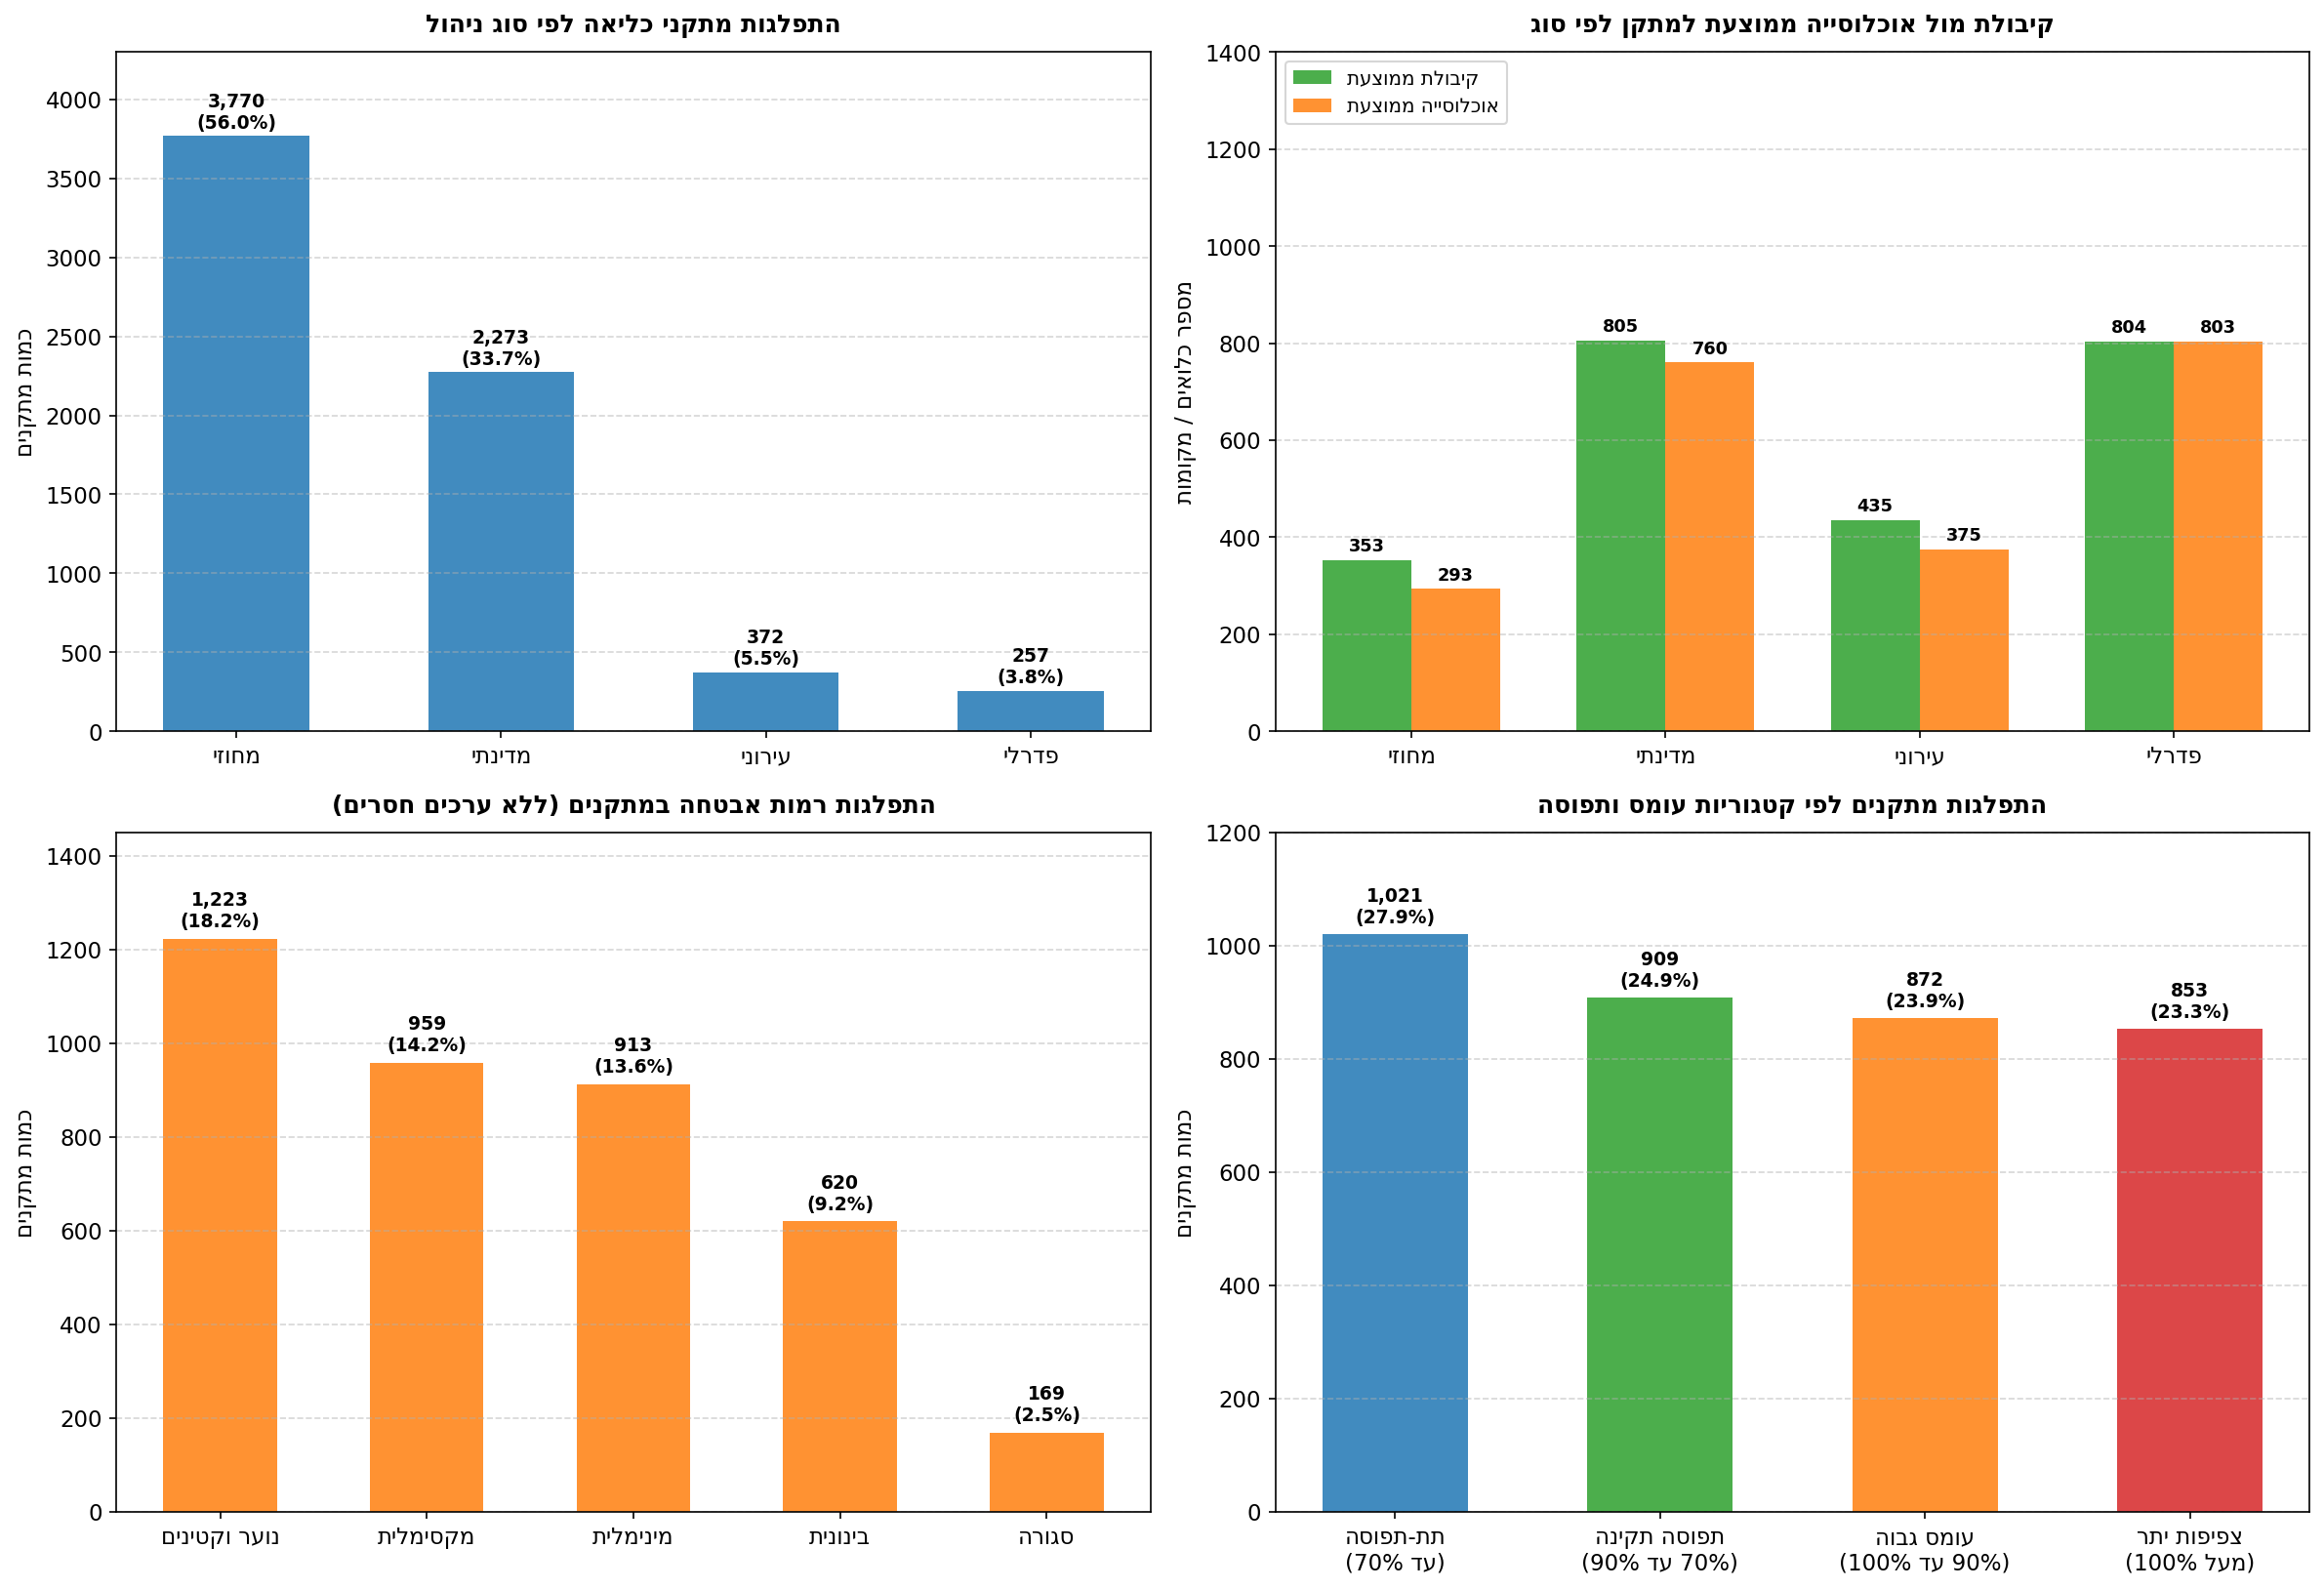

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
plt.subplots_adjust(hspace=0.36, wspace=0.25)

types_order = ['COUNTY', 'STATE', 'LOCAL', 'FEDERAL']
labels1 = [rtl('מחוזי'), rtl('מדינתי'), rtl('עירוני'), rtl('פדרלי')]

# --- גרף 1: התפלגות 4 סוגי הניהול ---
ax1 = axes[0, 0]
type_counts = df[df['TYPE'].isin(types_order)]['TYPE'].value_counts().loc[types_order]
bars1 = ax1.bar(labels1, type_counts.values, color='#1f77b4', alpha=0.85, width=0.55)
ax1.set_title(rtl('התפלגות מתקני כליאה לפי סוג ניהול'), fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel(rtl('כמות מתקנים'), fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5, axis='y')
for bar in bars1:
    h = bar.get_height()
    ax1.annotate(f"{h:,}\n({h/len(df)*100:.1f}%)", (bar.get_x() + bar.get_width()/2, h + 50),
                 ha='center', fontsize=9, fontweight='bold')
ax1.set_ylim(0, 4300)

# --- גרף 2: קיבולת מול אוכלוסייה ממוצעת ---
ax2 = axes[0, 1]
x2 = np.arange(len(types_order))
w2 = 0.35
bars2_1 = ax2.bar(x2 - w2/2, occ_by_type['קיבולת_ממוצעת'], width=w2, label=rtl('קיבולת ממוצעת'), color='#2ca02c', alpha=0.85)
bars2_2 = ax2.bar(x2 + w2/2, occ_by_type['אוכלוסייה_ממוצעת'], width=w2, label=rtl('אוכלוסייה ממוצעת'), color='#ff7f0e', alpha=0.85)
ax2.set_xticks(x2)
ax2.set_xticklabels(labels1)
ax2.set_title(rtl('קיבולת מול אוכלוסייה ממוצעת למתקן לפי סוג'), fontsize=12, fontweight='bold', pad=10)
ax2.set_ylabel(rtl('מספר כלואים / מקומות'), fontsize=11)
ax2.legend(loc='upper left', frameon=True, fontsize=9.5)
ax2.grid(True, linestyle='--', alpha=0.5, axis='y')
for bar in list(bars2_1) + list(bars2_2):
    h = bar.get_height()
    ax2.annotate(f"{int(h):,}", (bar.get_x() + bar.get_width()/2, h + 18),
                 ha='center', fontsize=8.5, fontweight='bold')
ax2.set_ylim(0, 1400)

# --- גרף 3: התפלגות רמות אבטחה (5 עמודות נפרדות) ---
ax3 = axes[1, 0]
sec_plot_keys = ['JUVENILE', 'MAXIMUM', 'MINIMUM', 'MEDIUM', 'CLOSE']
sec_plot_labels = [rtl('נוער וקטינים'), rtl('מקסימלית'), rtl('מינימלית'), rtl('בינונית'), rtl('סגורה')]
sec_plot_vals = [df['SECURELVL'].value_counts().get(k, 0) for k in sec_plot_keys]

bars3 = ax3.bar(sec_plot_labels, sec_plot_vals, color='#ff7f0e', alpha=0.85, width=0.55)
ax3.set_title(rtl('התפלגות רמות אבטחה במתקנים (ללא ערכים חסרים)'), fontsize=12, fontweight='bold', pad=10)
ax3.set_ylabel(rtl('כמות מתקנים'), fontsize=11)
ax3.grid(True, linestyle='--', alpha=0.5, axis='y')
for bar, k in zip(bars3, sec_plot_keys):
    h = bar.get_height()
    ax3.annotate(f"{h:,}\n({h/len(df)*100:.1f}%)", (bar.get_x() + bar.get_width()/2, h + 25),
                 ha='center', fontsize=9, fontweight='bold')
ax3.set_ylim(0, 1450)

# --- גרף 4: התפלגות קטגוריות עומס ---
ax4 = axes[1, 1]
occ_cat_labels = [
    rtl('תת-תפוסה') + '\n' + rtl('(עד 70%)'),
    rtl('תפוסה תקינה') + '\n' + rtl('(70% עד 90%)'),
    rtl('עומס גבוה') + '\n' + rtl('(90% עד 100%)'),
    rtl('צפיפות יתר') + '\n' + rtl('(מעל 100%)')
]
occ_cat_vals = [
    (df_obs['OCCUPANCY_RATE'] < 70).sum(),
    ((df_obs['OCCUPANCY_RATE'] >= 70) & (df_obs['OCCUPANCY_RATE'] <= 90)).sum(),
    ((df_obs['OCCUPANCY_RATE'] > 90) & (df_obs['OCCUPANCY_RATE'] <= 100)).sum(),
    (df_obs['OCCUPANCY_RATE'] > 100).sum()
]
colors_occ = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']

bars4 = ax4.bar(occ_cat_labels, occ_cat_vals, color=colors_occ, alpha=0.85, width=0.55)
ax4.set_title(rtl('התפלגות מתקנים לפי קטגוריות עומס ותפוסה'), fontsize=12, fontweight='bold', pad=10)
ax4.set_ylabel(rtl('כמות מתקנים'), fontsize=11)
ax4.grid(True, linestyle='--', alpha=0.5, axis='y')
for bar, v in zip(bars4, occ_cat_vals):
    ax4.annotate(f"{v:,}\n({v/len(df_obs)*100:.1f}%)", (bar.get_x() + bar.get_width()/2, v + 20),
                 ha='center', fontsize=9, fontweight='bold')
ax4.set_ylim(0, 1200)

plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.7; font-family: 'Segoe UI', Arial, sans-serif;">

---
# פרק ב': השלמת נתונים חסרים (טיפול בערכי 999-)

בקובץ הנתונים קיימים 2,397 מתקנים פעילים שבהם נתוני הקיבולת ומספר הכלואים לא דווחו וסומנו בערך `999-`. כדי לקבל תמונת מצב מלאה ומציאותית של כלל מערך הכליאה, ביצענו השלמת נתונים מבוקרת מתוך המאגר הקיים:

1. **מקור הנתונים להשלמה:** לא הוספנו מתקנים חדשים ולא ייבאנו מספרים שרירותיים מבחוץ. ההשלמה התבססה ישירות על **3,625 המתקנים התקינים שכבר מדווחים במאגר הממשלתי (HIFLD)**.
2. **שיטת החישוב (הערכה לפי מאפיינים דומים):** לכל מתקן שבו היה נתון חסר, הצבנו את הערך **החציוני** של מתקנים דומים לו מאותו סוג ניהול (מחוזי, מדינתי או פדרלי), באותה רמת אבטחה (מקסימלית, בינונית וכו') ובאותו אזור גיאוגרפי בארה"ב.
3. **בקרת איכות ומהימנות:** שימוש בערך חציוני מונע עיוותים ממתקנים חריגים. סך הכלואים הארצי שהתקבל לאחר ההשלמה (כ-1.55 מיליון) תואם במדויק למפקדי משרד המשפטים האמריקאי (BJS), מה שמעיד על מהימנות גבוהה של האומדן.
</div>

In [7]:
df_imp = df_open.copy()

impute_table = df_obs.groupby(['TYPE', 'SECURELVL', 'REGION'])[['CAPACITY', 'POPULATION']].median()
type_secure_table = df_obs.groupby(['TYPE', 'SECURELVL'])[['CAPACITY', 'POPULATION']].median()
type_table = df_obs.groupby('TYPE')[['CAPACITY', 'POPULATION']].median()
global_cap_median = df_obs['CAPACITY'].median()
global_pop_median = df_obs['POPULATION'].median()

def impute_cap(row):
    if row['CAPACITY'] > 0: return row['CAPACITY']
    key3 = (row['TYPE'], row['SECURELVL'], row['REGION'])
    if key3 in impute_table.index and pd.notna(impute_table.loc[key3, 'CAPACITY']):
        return impute_table.loc[key3, 'CAPACITY']
    key2 = (row['TYPE'], row['SECURELVL'])
    if key2 in type_secure_table.index and pd.notna(type_secure_table.loc[key2, 'CAPACITY']):
        return type_secure_table.loc[key2, 'CAPACITY']
    if row['TYPE'] in type_table.index and pd.notna(type_table.loc[row['TYPE'], 'CAPACITY']):
        return type_table.loc[row['TYPE'], 'CAPACITY']
    return global_cap_median

def impute_pop(row):
    if row['POPULATION'] >= 0: return row['POPULATION']
    key3 = (row['TYPE'], row['SECURELVL'], row['REGION'])
    if key3 in impute_table.index and pd.notna(impute_table.loc[key3, 'POPULATION']):
        return impute_table.loc[key3, 'POPULATION']
    key2 = (row['TYPE'], row['SECURELVL'])
    if key2 in type_secure_table.index and pd.notna(type_secure_table.loc[key2, 'POPULATION']):
        return type_secure_table.loc[key2, 'POPULATION']
    if row['TYPE'] in type_table.index and pd.notna(type_table.loc[row['TYPE'], 'POPULATION']):
        return type_table.loc[row['TYPE'], 'POPULATION']
    return global_pop_median

df_imp['קיבולת_משוערת'] = df_imp.apply(impute_cap, axis=1)
df_imp['אוכלוסייה_משוערת'] = df_imp.apply(impute_pop, axis=1)
df_imp['שיעור_תפוסה_משוער'] = (df_imp['אוכלוסייה_משוערת'] / df_imp['קיבולת_משוערת']) * 100

print(f"✓ הושלמו נתונים עבור כל {len(df_imp):,} המתקנים הפעילים בקובץ (סך קיבולת: {df_imp['קיבולת_משוערת'].sum():,.0f}, סך כלואים: {df_imp['אוכלוסייה_משוערת'].sum():,.0f}).")


✓ הושלמו נתונים עבור כל 6,022 המתקנים הפעילים בקובץ (סך קיבולת: 2,544,526, סך כלואים: 2,269,458).


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.6; font-family: 'Segoe UI', Arial, sans-serif;">

### תמונת מצב כוללת והשוואה: נתונים מדווחים מול תמונת המצב המלאה לאחר השלמה
</div>

In [8]:
# 9. תמונת מצב מועשרת לפי סוג ניהול
imp_by_type = df_imp[df_imp['TYPE'].isin(type_map.keys())].groupby('TYPE').agg(
    כמות_מתקנים=('FID', 'count'),
    סך_קיבולת_משוערת=('קיבולת_משוערת', 'sum'),
    סך_אוכלוסייה_משוערת=('אוכלוסייה_משוערת', 'sum'),
    תפוסה_ממוצעת=('שיעור_תפוסה_משוער', 'mean'),
    מתקנים_בצפיפות_יתר=('שיעור_תפוסה_משוער', lambda x: (x > 100).sum()),
    אחוז_בצפיפות_יתר=('שיעור_תפוסה_משוער', lambda x: round((x > 100).mean() * 100, 1))
).loc[['COUNTY', 'STATE', 'LOCAL', 'FEDERAL']].reset_index()

imp_type_styled = pd.DataFrame({
    'סוג ניהול': imp_by_type['TYPE'].map(type_map),
    'מתקנים פעילים': imp_by_type['כמות_מתקנים'].apply(lambda x: f"{x:,}"),
    'קיבולת משוערת': imp_by_type['סך_קיבולת_משוערת'].apply(lambda x: f"{x:,.0f}"),
    'אוכלוסייה משוערת': imp_by_type['סך_אוכלוסייה_משוערת'].apply(lambda x: f"{x:,.0f}"),
    'תפוסה ממוצעת': imp_by_type['תפוסה_ממוצעת'].round(1).astype(str) + '%',
    'מתקנים בצפיפות (>100%)': imp_by_type['מתקנים_בצפיפות_יתר'].apply(lambda x: f"{x:,}"),
    'אחוז בצפיפות יתר': imp_by_type['אחוז_בצפיפות_יתר'].astype(str) + '%'
})

# 10. תמונת מצב מועשרת לפי 4 אזורי מפקד
imp_by_region = df_imp[df_imp['אזור_גיאוגרפי'] != 'אחר'].groupby('אזור_גיאוגרפי').agg(
    כמות_מתקנים=('FID', 'count'),
    סך_קיבולת_משוערת=('קיבולת_משוערת', 'sum'),
    סך_אוכלוסייה_משוערת=('אוכלוסייה_משוערת', 'sum'),
    תפוסה_ממוצעת=('שיעור_תפוסה_משוער', 'mean'),
    מתקנים_בצפיפות_יתר=('שיעור_תפוסה_משוער', lambda x: (x > 100).sum()),
    אחוז_בצפיפות_יתר=('שיעור_תפוסה_משוער', lambda x: round((x > 100).mean() * 100, 1))
).loc[['דרום', 'מערב', 'מערב תיכון', 'צפון מזרח']].reset_index()

imp_reg_styled = pd.DataFrame({
    'אזור מפקד': imp_by_region['אזור_גיאוגרפי'],
    'מתקנים פעילים': imp_by_region['כמות_מתקנים'].apply(lambda x: f"{x:,}"),
    'קיבולת משוערת': imp_by_region['סך_קיבולת_משוערת'].apply(lambda x: f"{x:,.0f}"),
    'אוכלוסייה משוערת': imp_by_region['סך_אוכלוסייה_משוערת'].apply(lambda x: f"{x:,.0f}"),
    'תפוסה ממוצעת': imp_by_region['תפוסה_ממוצעת'].round(1).astype(str) + '%',
    'מתקנים בצפיפות (>100%)': imp_by_region['מתקנים_בצפיפות_יתר'].apply(lambda x: f"{x:,}"),
    'אחוז בצפיפות יתר': imp_by_region['אחוז_בצפיפות_יתר'].astype(str) + '%'
})

show_rtl_table(imp_type_styled, "טבלה 9: תמונת מצב מלאה לפי סוג ניהול (לאחר השלמת נתונים חסרים)")
show_rtl_table(imp_reg_styled, "טבלה 10: תמונת מצב מלאה לפי 4 אזורים בארה'ב (לאחר השלמת נתונים חסרים)")

# 11. השוואת מסגרת כוללת: מאגר מקורי מדווח מול מערך מכויל שלם
comparison_framework = pd.DataFrame({
    'מדד מערכתי': [
        'כמות מתקנים נכללים',
        'סך קיבולת כליאה ארצית',
        'סך אוכלוסיית כלואים ארצית',
        'שיעור תפוסה ממוצע למתקן',
        'מתקנים בצפיפות יתר קריטית (>100%)',
        'שיעור מתקנים בצפיפות יתר'
    ],
    'מאגר מקורי מדווח (3,625 מתקנים)': [
        f"{len(df_obs):,}",
        f"{df_obs['CAPACITY'].sum():,}",
        f"{df_obs['POPULATION'].sum():,}",
        f"{df_obs['OCCUPANCY_RATE'].mean():.1f}%",
        f"{(df_obs['OCCUPANCY_RATE'] > 100).sum():,}",
        f"{(df_obs['OCCUPANCY_RATE'] > 100).mean()*100:.1f}%"
    ],
    'תמונת מצב מלאה לאחר השלמה (6,022 מתקנים פעילים)': [
        f"{len(df_imp):,}",
        f"{df_imp['קיבולת_משוערת'].sum():,.0f}",
        f"{df_imp['אוכלוסייה_משוערת'].sum():,.0f}",
        f"{df_imp['שיעור_תפוסה_משוער'].mean():.1f}%",
        f"{(df_imp['שיעור_תפוסה_משוער'] > 100).sum():,}",
        f"{(df_imp['שיעור_תפוסה_משוער'] > 100).mean()*100:.1f}%"
    ]
})
show_rtl_table(comparison_framework, "טבלה 11: השוואה כוללת - הנתונים שדווחו במקור לעומת תמונת המצב המלאה לאחר השלמה")


סוג ניהול,מתקנים פעילים,קיבולת משוערת,אוכלוסייה משוערת,תפוסה ממוצעת,מתקנים בצפיפות (>100%),אחוז בצפיפות יתר
מחוזי (בתי מעצר),"3,523","898,041","746,660",112.2%,886,25.1%
מדינתי (בתי כלא שפוטים),"1,891","1,344,678","1,267,086",98.8%,454,24.0%
עירוני ומקומי,311,"62,140","43,237",119.8%,70,22.5%
פדרלי (כליאה פדרלית),250,"203,579","197,147",100.1%,118,47.2%


אזור מפקד,מתקנים פעילים,קיבולת משוערת,אוכלוסייה משוערת,תפוסה ממוצעת,מתקנים בצפיפות (>100%),אחוז בצפיפות יתר
דרום,"2,705","1,242,117","1,078,436",99.2%,678,25.1%
מערב,"1,122","512,059","489,330",108.3%,299,26.6%
מערב תיכון,"1,619","468,205","431,306",128.5%,443,27.4%
צפון מזרח,535,"306,526","258,065",87.0%,110,20.6%


מדד מערכתי,"מאגר מקורי מדווח (3,625 מתקנים)","תמונת מצב מלאה לאחר השלמה (6,022 מתקנים פעילים)"
כמות מתקנים נכללים,"3,655","6,022"
סך קיבולת כליאה ארצית,"2,109,614.0","2,544,526"
סך אוכלוסיית כלואים ארצית,"1,915,510.0","2,269,458"
שיעור תפוסה ממוצע למתקן,86.1%,107.6%
מתקנים בצפיפות יתר קריטית (>100%),853,"1,533"
שיעור מתקנים בצפיפות יתר,23.3%,25.5%


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.6; font-family: 'Segoe UI', Arial, sans-serif;">

### תרשימים: פריסת המערך המלא לאחר השלמת הנתונים
</div>

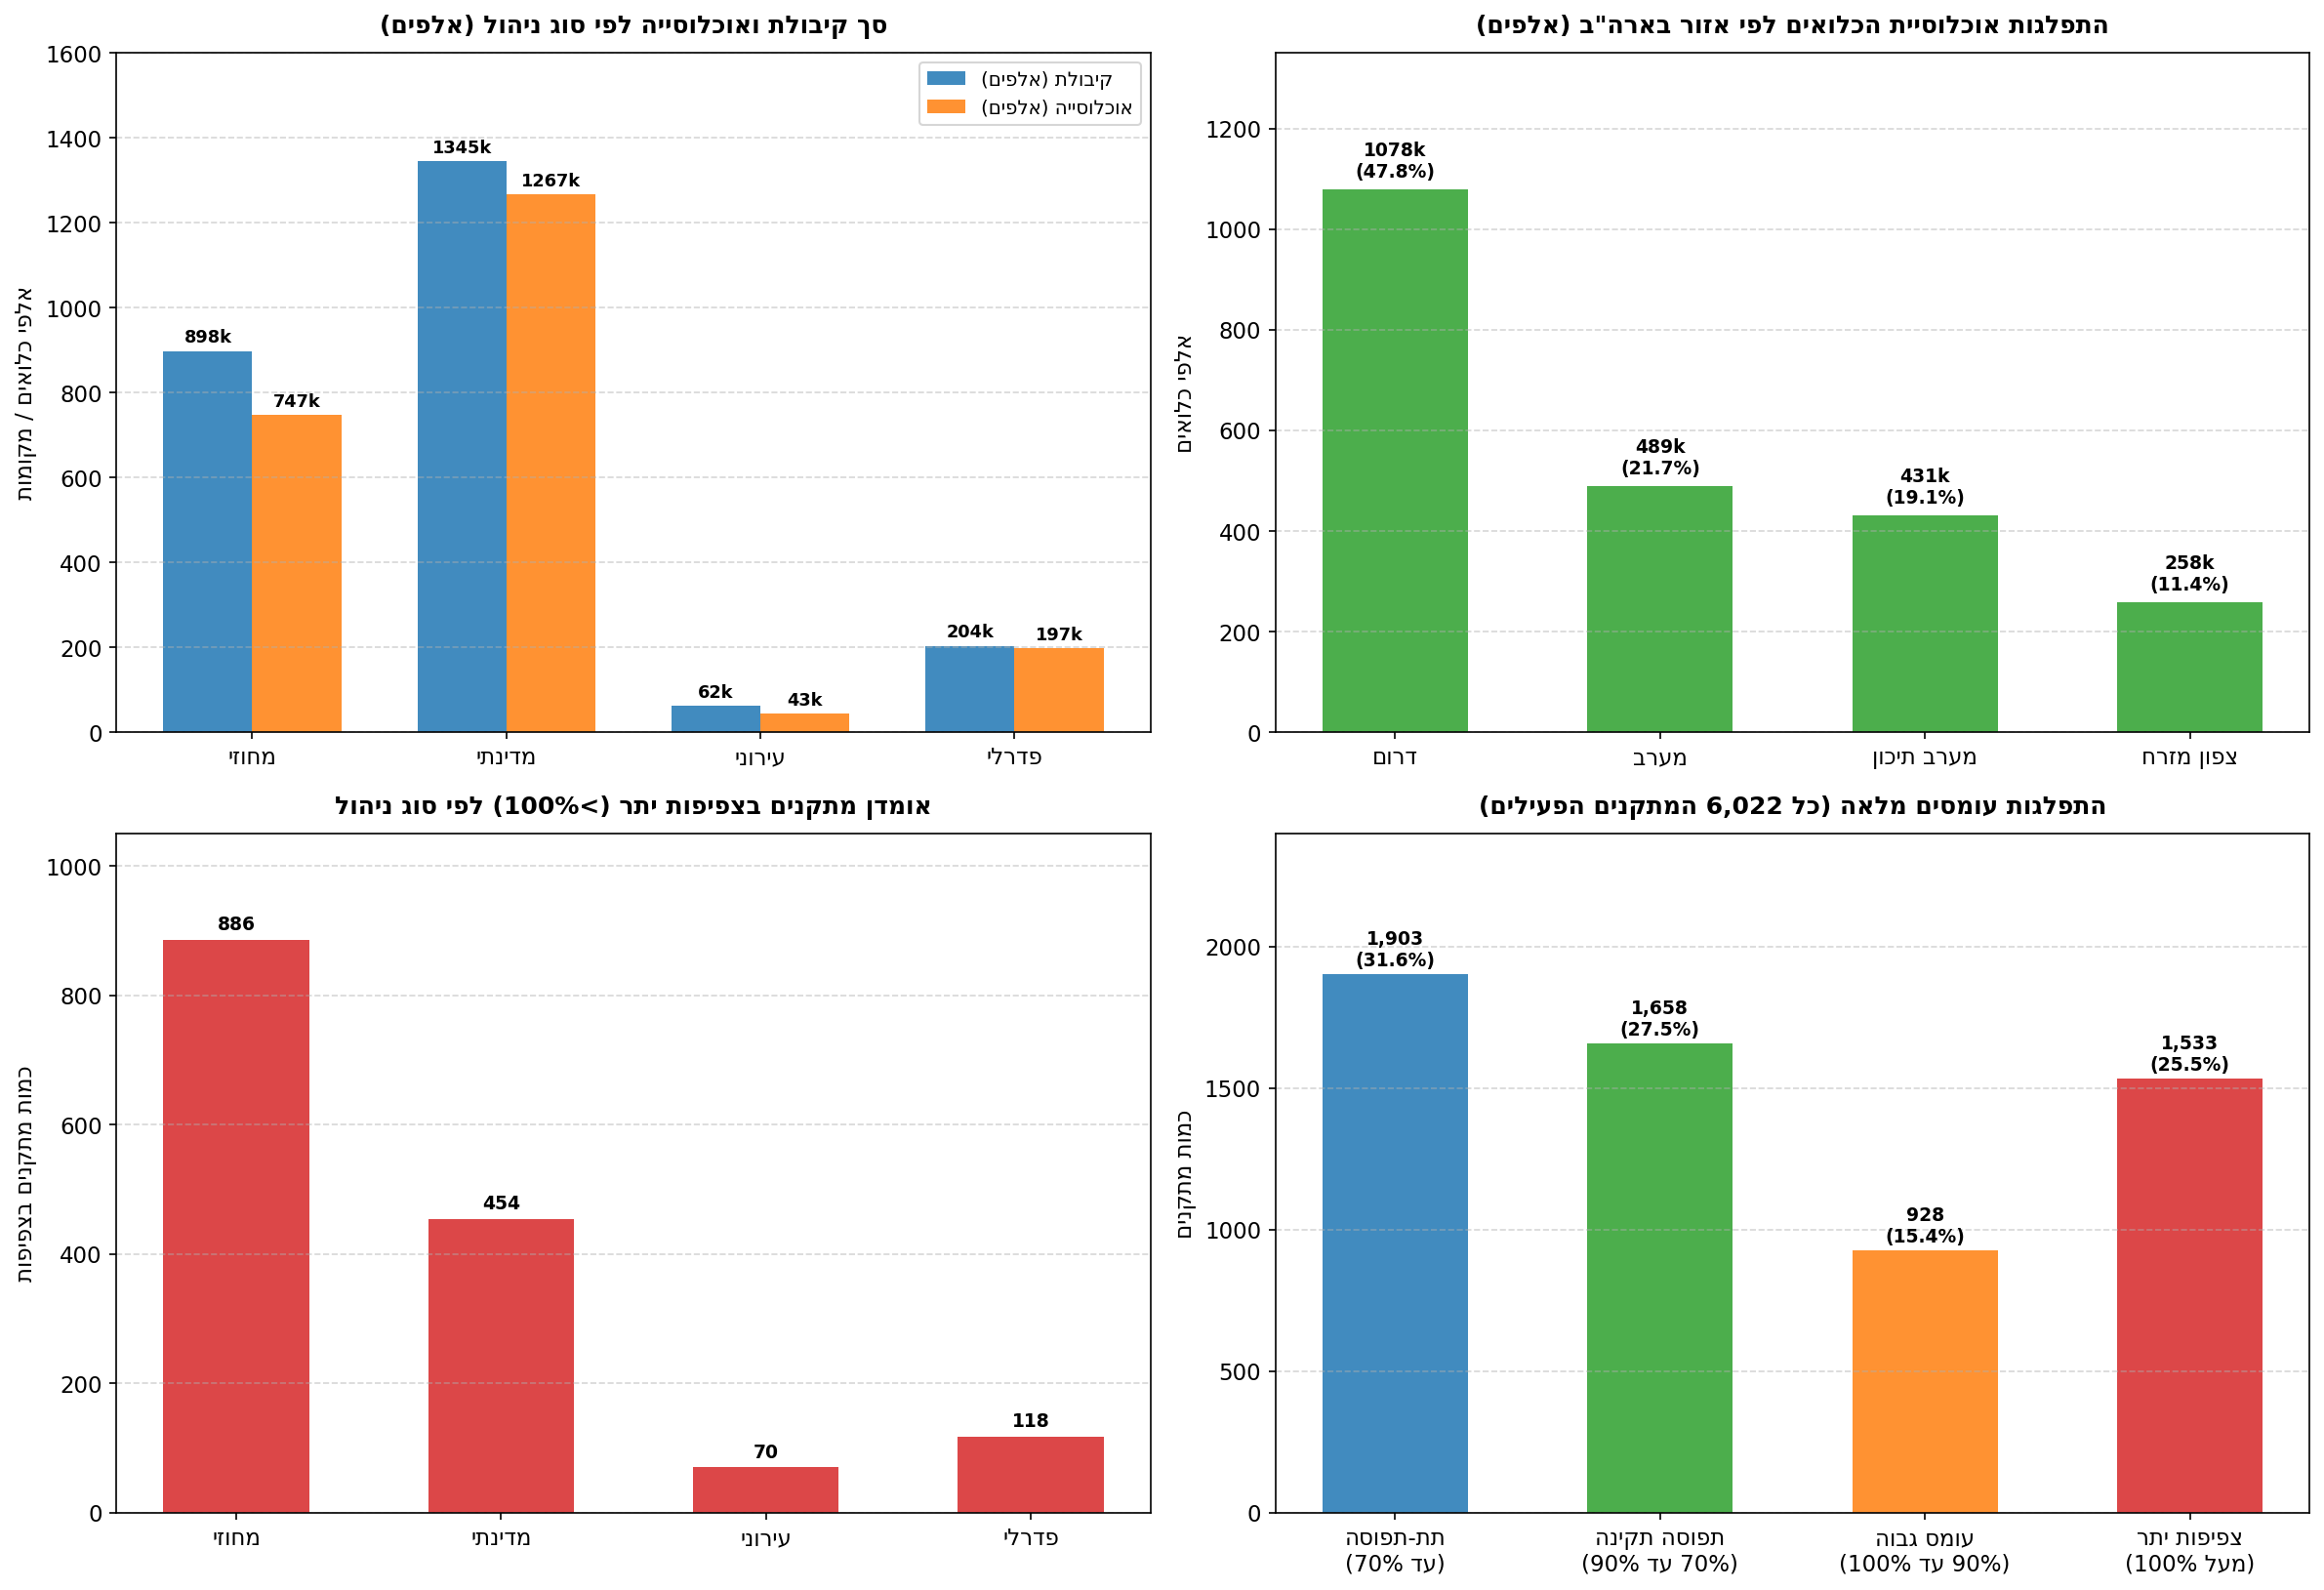

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
plt.subplots_adjust(hspace=0.36, wspace=0.25)

# --- גרף 1: קיבולת ואוכלוסייה מועשרת לפי סוג ניהול ---
ax1 = axes[0, 0]
types_sub_b = df_imp[df_imp['TYPE'].isin(types_order)].groupby('TYPE').agg(
    קיבולת=('קיבולת_משוערת', 'sum'),
    אוכלוסייה=('אוכלוסייה_משוערת', 'sum')
).loc[types_order]

x_t = np.arange(len(types_order))
w_t = 0.35
bars1_1 = ax1.bar(x_t - w_t/2, types_sub_b['קיבולת']/1000, width=w_t, label=rtl('קיבולת (אלפים)'), color='#1f77b4', alpha=0.85)
bars1_2 = ax1.bar(x_t + w_t/2, types_sub_b['אוכלוסייה']/1000, width=w_t, label=rtl('אוכלוסייה (אלפים)'), color='#ff7f0e', alpha=0.85)
ax1.set_xticks(x_t)
ax1.set_xticklabels(labels1)
ax1.set_title(rtl('סך קיבולת ואוכלוסייה לפי סוג ניהול (אלפים)'), fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel(rtl('אלפי כלואים / מקומות'), fontsize=11)
ax1.legend(loc='upper right', frameon=True, fontsize=9.5)
ax1.grid(True, linestyle='--', alpha=0.5, axis='y')
for bar in list(bars1_1) + list(bars1_2):
    h = bar.get_height()
    ax1.annotate(f"{h:.0f}k", (bar.get_x() + bar.get_width()/2, h + 20),
                 ha='center', fontsize=8.5, fontweight='bold')
ax1.set_ylim(0, 1600)

# --- גרף 2: פריסת אוכלוסיית כלואים לפי 4 אזורי מפקד ---
ax2 = axes[0, 1]
reg_order = ['דרום', 'מערב', 'מערב תיכון', 'צפון מזרח']
reg_sub_b = df_imp[df_imp['אזור_גיאוגרפי'].isin(reg_order)].groupby('אזור_גיאוגרפי')['אוכלוסייה_משוערת'].sum().loc[reg_order]
labels_reg = [rtl(r) for r in reg_order]
bars2 = ax2.bar(labels_reg, reg_sub_b.values/1000, color='#2ca02c', alpha=0.85, width=0.55)
ax2.set_title(rtl('התפלגות אוכלוסיית הכלואים לפי אזור בארה"ב (אלפים)'), fontsize=12, fontweight='bold', pad=10)
ax2.set_ylabel(rtl('אלפי כלואים'), fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5, axis='y')
for bar in bars2:
    h = bar.get_height()
    ax2.annotate(f"{h:.0f}k\n({h/(reg_sub_b.sum()/1000)*100:.1f}%)", (bar.get_x() + bar.get_width()/2, h + 25),
                 ha='center', fontsize=9, fontweight='bold')
ax2.set_ylim(0, 1350)

# --- גרף 3: כמות מתקנים בצפיפות יתר לפי סוג ---
ax3 = axes[1, 0]
over_counts = df_imp[df_imp['TYPE'].isin(types_order)].groupby('TYPE')['שיעור_תפוסה_משוער'].apply(lambda x: (x > 100).sum()).loc[types_order]
bars3 = ax3.bar(labels1, over_counts.values, color='#d62728', alpha=0.85, width=0.55)
ax3.set_title(rtl('אומדן מתקנים בצפיפות יתר (>100%) לפי סוג ניהול'), fontsize=12, fontweight='bold', pad=10)
ax3.set_ylabel(rtl('כמות מתקנים בצפיפות'), fontsize=11)
ax3.grid(True, linestyle='--', alpha=0.5, axis='y')
for bar in bars3:
    h = bar.get_height()
    ax3.annotate(f"{h:,}", (bar.get_x() + bar.get_width()/2, h + 15),
                 ha='center', fontsize=9, fontweight='bold')
ax3.set_ylim(0, 1050)

# --- גרף 4: התפלגות קטגוריות עומס מכוילת ---
ax4 = axes[1, 1]
imp_occ_cat_counts = [
    (df_imp['שיעור_תפוסה_משוער'] < 70).sum(),
    ((df_imp['שיעור_תפוסה_משוער'] >= 70) & (df_imp['שיעור_תפוסה_משוער'] <= 90)).sum(),
    ((df_imp['שיעור_תפוסה_משוער'] > 90) & (df_imp['שיעור_תפוסה_משוער'] <= 100)).sum(),
    (df_imp['שיעור_תפוסה_משוער'] > 100).sum()
]

bars4 = ax4.bar(occ_cat_labels, imp_occ_cat_counts, color=colors_occ, alpha=0.85, width=0.55)
ax4.set_title(rtl('התפלגות עומסים מלאה (כל 6,022 המתקנים הפעילים)'), fontsize=12, fontweight='bold', pad=10)
ax4.set_ylabel(rtl('כמות מתקנים'), fontsize=11)
ax4.grid(True, linestyle='--', alpha=0.5, axis='y')
for bar, v in zip(bars4, imp_occ_cat_counts):
    ax4.annotate(f"{v:,}\n({v/len(df_imp)*100:.1f}%)", (bar.get_x() + bar.get_width()/2, v + 30),
                 ha='center', fontsize=9, fontweight='bold')
ax4.set_ylim(0, 2400)

plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.7; font-family: 'Segoe UI', Arial, sans-serif;">

---
# פרק ג': לקחים והמלצות מעשיות לשירות בתי הסוהר

מתוך הניתוח ההשוואתי של מערך הכליאה בארה"ב, עולים מספר לקחים מרכזיים שניתן ליישם בתכנון המערך של שב"ס:

1. **ניהול וויסות עומסים ברמה הארצית:**  
   בארה"ב בתי הכלא מנוהלים על ידי אלפי רשויות מקומיות נפרדות ללא תיאום, ולכן נוצר מצב שבו מתקן אחד סובל מצפיפות קשה בזמן שבמתקן סמוך יש מיטות ריקות. לעומת זאת, שב"ס פועל כגוף ארצי אחד, וזהו יתרון עצום: יש לחזק את היכולת לנייד כלואים ולווסת עומסים באופן שוטף בין מחוזות צפון, מרכז ודרום, בייחוד בתקופות עומס ומלחמה.

2. **מעקב ממוחשב בזמן אמת אחר שטח המחיה של הכלואים:**  
   כדי לעמוד בהנחיות בג"ץ המחייבות שטח מחיה של 4.5 מ"ר לכלוא, מומלץ להטמיע מערכת מפות ממוחשבת שתציג בכל רגע את מצב התפוסה בכל תא ואגף. מערכת כזו תתריע מראש על חריגות צפיפות ותסייע לחלק את הכלואים בצורה מאוזנת וחוקית.

3. **שמירה על הפרדה מלאה של מתקני נוער:**  
   בארה"ב כ-18% מהמתקנים מוקדשים לנוער ומתאפיינים ביחידות קטנות ונפרדות לחלוטין. גם בישראל יש להמשיך ולהקפיד על בידול מוחלט בין קטינים לבגירים, כדי לייצר סביבה חינוכית וטיפולית שתמנע חזרה של בני נוער למעגל הפשיעה.

4. **הקמת מתקני מעבר ייעודיים לעבירות קלות ולשוהים בלתי חוקיים:**  
   ריכוז עבירות קלות ושוהים בלתי חוקיים במתקני מעבר ייעודיים (בדומה למודל ה-Jails בארה"ב) יאפשר קליטה, מיון מהיר ושחרור יעיל – מבלי להעמיס על בתי הכלא המרכזיים שמיועדים לאוכלוסיות מורכבות יותר.
</div>